# Victorian Electricity Demand: Data Acquisition

This notebook retrieves, validates, aggregates and saves Victorian electricity demand data for 2025 using AEMO market data.

## 1. Setup

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from nemosis import dynamic_data_compiler

print("Setup complete")

Setup complete


In [18]:
PROJECT_ROOT = Path.cwd().parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

print(PROJECT_ROOT)
print(RAW_DATA_DIR)

/Users/mani/Desktop/Projects/victorian-electricity-demand
/Users/mani/Desktop/Projects/victorian-electricity-demand/data/raw


## 2. Retrieve Victorian Demand Data

Retrieve 5-minute Victorian electricity demand observations for the 2025 calendar year.

In [19]:
start_time = "2025/01/01 00:00:00"
end_time = "2026/01/01 00:00:00"

demand_5min = dynamic_data_compiler(
    start_time=start_time,
    end_time=end_time,
    table_name="DISPATCHREGIONSUM",
    raw_data_location=str(RAW_DATA_DIR),
    select_columns=[
        "SETTLEMENTDATE",
        "REGIONID",
        "INTERVENTION",
        "TOTALDEMAND"
    ],
    filter_cols=["REGIONID", "INTERVENTION"],
    filter_values=(["VIC1"], [0])
)

INFO: Compiling data for table DISPATCHREGIONSUM
INFO: Returning DISPATCHREGIONSUM.


## 3. Inspect and Validate Raw Data

Check the structure, time coverage, missing values, duplicates and interval consistency before using the data for analysis.

In [20]:
print("Shape:", demand_5min.shape)

print("\nFirst rows:")
display(demand_5min.head())

print("\nLast rows:")
display(demand_5min.tail())

print("\nData types:")
print(demand_5min.dtypes)

Shape: (105120, 4)

First rows:


,SETTLEMENTDATE,REGIONID,INTERVENTION,TOTALDEMAND
4,2025-01-01 00:05:00,VIC1,0,4339.00
9,2025-01-01 00:10:00,VIC1,0,4310.79
14,2025-01-01 00:15:00,VIC1,0,4243.74
19,2025-01-01 00:20:00,VIC1,0,4269.83
25,2025-01-01 00:25:00,VIC1,0,4242.11



Last rows:


,SETTLEMENTDATE,REGIONID,INTERVENTION,TOTALDEMAND
44619,2025-12-31 23:40:00,VIC1,0,4242.66
44624,2025-12-31 23:45:00,VIC1,0,4218.78
44630,2025-12-31 23:50:00,VIC1,0,4201.52
44634,2025-12-31 23:55:00,VIC1,0,4162.44
44639,2026-01-01 00:00:00,VIC1,0,4136.51



Data types:
SETTLEMENTDATE    datetime64[us]
REGIONID                     str
INTERVENTION               int64
TOTALDEMAND              float64
dtype: object


In [21]:
demand_5min["SETTLEMENTDATE"] = pd.to_datetime(
    demand_5min["SETTLEMENTDATE"]
)

demand_5min = (
    demand_5min
    .sort_values("SETTLEMENTDATE")
    .reset_index(drop=True)
)

In [22]:
print("Start:", demand_5min["SETTLEMENTDATE"].min())
print("End:", demand_5min["SETTLEMENTDATE"].max())

print("\nMissing values:")
print(demand_5min.isna().sum())

print("\nDuplicate rows:")
print(demand_5min.duplicated().sum())

print("\nDemand summary:")
print(demand_5min["TOTALDEMAND"].describe())

Start: 2025-01-01 00:05:00
End: 2026-01-01 00:00:00

Missing values:
SETTLEMENTDATE    0
REGIONID          0
INTERVENTION      0
TOTALDEMAND       0
dtype: int64

Duplicate rows:
0

Demand summary:
count    105120.000000
mean       4881.166142
std        1186.561979
min        1224.770000
25%        4128.980000
50%        4764.390000
75%        5555.167500
max        9490.530000
Name: TOTALDEMAND, dtype: float64


In [23]:
time_gaps = (
    demand_5min["SETTLEMENTDATE"]
    .diff()
    .value_counts()
    .sort_index()
)

print(time_gaps.head(10))

SETTLEMENTDATE
0 days 00:05:00    105119
Name: count, dtype: int64


In [24]:
duplicate_timestamps = demand_5min[
    demand_5min["SETTLEMENTDATE"].duplicated(keep=False)
]

print("Duplicate timestamps:", len(duplicate_timestamps))

display(duplicate_timestamps.head(20))

Duplicate timestamps: 0


,SETTLEMENTDATE,REGIONID,INTERVENTION,TOTALDEMAND


## 4. Aggregate to 30 Minute Intervals

Aggregate the original 5-minute observations to 30-minute mean demand values for the main analytical dataset.

In [25]:
demand_30min = (
    demand_5min
    .set_index("SETTLEMENTDATE")["TOTALDEMAND"]
    .resample("30min")
    .mean()
    .reset_index()
)

demand_30min = demand_30min.rename(
    columns={
        "SETTLEMENTDATE": "datetime",
        "TOTALDEMAND": "demand_mw"
    }
)

display(demand_30min.head())

print("\nShape:", demand_30min.shape)

,datetime,demand_mw
0,2025-01-01 00:00:00,4281.094000
1,2025-01-01 00:30:00,4180.268333
2,2025-01-01 01:00:00,4093.626667
3,2025-01-01 01:30:00,3985.283333
4,2025-01-01 02:00:00,3876.845000



Shape: (17521, 2)


In [26]:
demand_30min = demand_30min[
    demand_30min["datetime"] < "2026-01-01"
].copy()

print("Shape:", demand_30min.shape)
print("Start:", demand_30min["datetime"].min())
print("End:", demand_30min["datetime"].max())

Shape: (17520, 2)
Start: 2025-01-01 00:00:00
End: 2025-12-31 23:30:00


## 5. Validate Processed Dataset

Confirm that the final 30-minute dataset has the expected number of observations, no missing demand values and sensible summary statistics.

In [27]:
print(demand_30min.info())

print("\nMissing values:")
print(demand_30min.isna().sum())

print("\nDemand summary:")
print(demand_30min["demand_mw"].describe())

<class 'pandas.DataFrame'>
RangeIndex: 17520 entries, 0 to 17519
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   datetime   17520 non-null  datetime64[us]
 1   demand_mw  17520 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 273.9 KB
None

Missing values:
datetime     0
demand_mw    0
dtype: int64

Demand summary:
count    17520.000000
mean      4881.167518
std       1184.040775
min       1251.610000
25%       4133.692917
50%       4762.955833
75%       5550.887083
max       9421.428333
Name: demand_mw, dtype: float64


In [28]:
assert len(demand_30min) == 17520
assert demand_30min["datetime"].is_unique
assert demand_30min["datetime"].is_monotonic_increasing
assert demand_30min["demand_mw"].notna().all()

print("All validation checks passed.")

All validation checks passed.


## 6. Visual Check

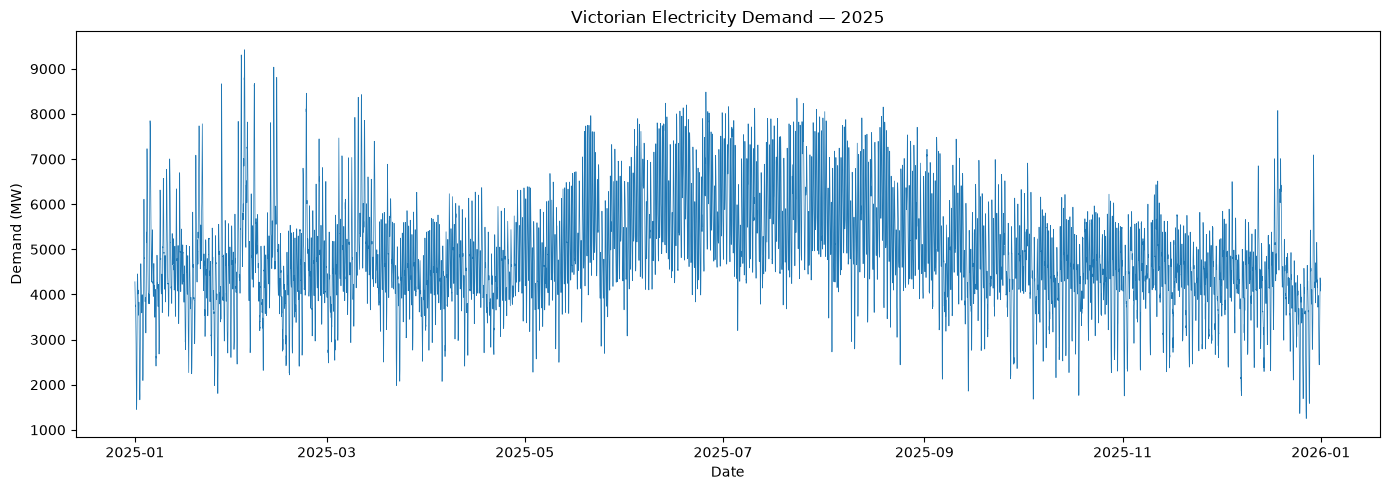

In [29]:
plt.figure(figsize=(14, 5))

plt.plot(
    demand_30min["datetime"],
    demand_30min["demand_mw"],
    linewidth=0.5
)

plt.title("Victorian Electricity Demand — 2025")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.tight_layout()

plt.show()

## 7. Save Processed Dataset

Save the validated 30-minute dataset for use in later exploratory analysis and modelling.

In [30]:
processed_path = PROCESSED_DATA_DIR / "vic_demand_2025_30min.parquet"

demand_30min.to_parquet(
    processed_path,
    index=False
)

print(f"Saved to: {processed_path}")

Saved to: /Users/mani/Desktop/Projects/victorian-electricity-demand/data/processed/vic_demand_2025_30min.parquet
